In [1]:
"""
Traffic-Aware Route Optimization using A* (FAI Mini-Project #11)
=================================================================
Dataset : sustainable_vehicle_routing.csv (GPS, speed, traffic, weather, fuel, CO2 ...)
Method  : The GPS area is divided into a grid of junctions. Edge costs (travel time,
          fuel, CO2) are learned from the dataset. A* is compared with Dijkstra,
          BFS and Greedy best-first search.

Run     : python traffic_route_optimization.py                (CSV next to this file)
          python traffic_route_optimization.py my_data.csv    (another CSV path)
          python traffic_route_optimization.py --no-show      (only save the charts)
Needs   : pip install pandas numpy matplotlib
"""
import heapq, math, random, sys, time
from collections import deque
from pathlib import Path

import matplotlib
if "--no-show" in sys.argv:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.collections import LineCollection

In [3]:
# ----------------------------------------------------------------- settings
GRID = 12                 # GRID x GRID junctions over the GPS area
MIN_OBS = 3               # a grid cell needs this many readings, else global average is used
TRIALS = 300              # random trips per scenario in the benchmark
SEED = 42
TRAFFIC_PEN = {"Low": 0.0, "Medium": 0.25, "High": 0.60}               # extra delay factor
ROAD_PEN = {"Dry": 0.0, "Wet": 0.10, "Icy": 0.30}
WEATHER_PEN = {"Clear": 0.0, "Rainy": 0.10, "Foggy": 0.15, "Stormy": 0.25}
SCENARIOS = ["All traffic", "Low traffic", "Medium traffic", "High traffic"]
ALGOS = ["A*", "Dijkstra", "BFS", "Greedy"]
COL = {"A*": "#2563EB", "Dijkstra": "#F59E0B", "BFS": "#8B5CF6", "Greedy": "#10B981"}
TCOL = {"Low": "#22C55E", "Medium": "#F59E0B", "High": "#EF4444"}
OUT = Path.cwd() / "results"

plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "#F8FAFC", "axes.edgecolor": "#CBD5E1",
                     "axes.grid": True, "grid.color": "#E2E8F0", "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10, "axes.titleweight": "bold"})


In [4]:
# ------------------------------------------------------------------ 1. data
def load_data(path):
    df = pd.read_csv(path, parse_dates=["timestamp"])
    raw = len(df)
    df = df.drop_duplicates().dropna()
    neg = int((df["fuel_consumption"] < 0).sum())
    df["fuel_consumption"] = df["fuel_consumption"].clip(lower=0)     # fuel cannot be negative
    df["penalty"] = (df["traffic_density"].map(TRAFFIC_PEN) + df["road_condition"].map(ROAD_PEN)
                     + df["weather_condition"].map(WEATHER_PEN))
    print(f"Loaded {raw} rows | after cleaning {len(df)} | negative fuel values fixed: {neg}")
    return df


def add_cells(df):
    b = (df.latitude.min(), df.latitude.max(), df.longitude.min(), df.longitude.max())
    df["ci"] = np.minimum(((df.latitude - b[0]) / (b[1] - b[0]) * GRID).astype(int), GRID - 1)
    df["cj"] = np.minimum(((df.longitude - b[2]) / (b[3] - b[2]) * GRID).astype(int), GRID - 1)
    return b

In [5]:
# ------------------------------------------------------- 2. road network
class Network:
    """Grid of junctions. Edge cost = distance / speed x (1 + delay) learned from the data."""

    def __init__(self, sub, bounds):
        la0, la1, lo0, lo1 = bounds
        stats = sub.groupby(["ci", "cj"]).agg(speed=("speed", "mean"), pen=("penalty", "mean"),
                                              co2=("co2_emission", "mean"), fuel=("fuel_consumption", "mean"),
                                              n=("speed", "size"))
        glob = {"speed": sub.speed.mean(), "pen": sub.penalty.mean(),
                "co2": sub.co2_emission.mean(), "fuel": sub.fuel_consumption.mean()}
        cell = {k: np.full((GRID, GRID), v) for k, v in glob.items()}
        for (i, j), r in stats.iterrows():
            if r.n >= MIN_OBS:
                for k in glob:
                    cell[k][i, j] = r[k]
        kx = 111.32 * math.cos(math.radians((la0 + la1) / 2))
        self.pos = {i * GRID + j: ((lo0 + (j + .5) * (lo1 - lo0) / GRID - lo0) * kx,
                                   (la0 + (i + .5) * (la1 - la0) / GRID - la0) * 110.57)
                    for i in range(GRID) for j in range(GRID)}
        self.adj, self.cellinfo = {u: {} for u in self.pos}, cell
        for i in range(GRID):
            for j in range(GRID):
                for di, dj in ((0, 1), (1, 0), (1, 1), (1, -1)):
                    a, b = (i, j), (i + di, j + dj)
                    if 0 <= b[0] < GRID and 0 <= b[1] < GRID:
                        u, v = a[0] * GRID + a[1], b[0] * GRID + b[1]
                        km = math.dist(self.pos[u], self.pos[v])
                        m = lambda k: (cell[k][a] + cell[k][b]) / 2
                        spd, f = m("speed"), 1 + m("pen")
                        e = {"km": km, "min": km / spd * 60 * f, "co2": km * m("co2"),
                             "fuel": km * m("fuel"), "f": f, "spd": spd}
                        self.adj[u][v] = self.adj[v][u] = e
        self.vmax = max(e["spd"] for u in self.adj for e in self.adj[u].values())

    def h(self, n, goal):  # straight-line time at the best speed -> never overestimates (admissible)
        return math.dist(self.pos[n], self.pos[goal]) / self.vmax * 60

    def nbrs(self, u, blocked):
        return [(v, e) for v, e in self.adj[u].items() if (min(u, v), max(u, v)) not in blocked]

In [6]:
# ------------------------------------------------------------ 3. algorithms
def solve(net, src, dst, algo, blocked=frozenset()):
    t0 = time.perf_counter()
    parent, explored, seen = {}, [], {src}
    if algo == "BFS":                                    # fewest junctions, ignores traffic
        q = deque([src])
        while q:
            u = q.popleft()
            explored.append(u)
            if u == dst:
                break
            for v, _ in net.nbrs(u, blocked):
                if v not in seen:
                    seen.add(v); parent[v] = u; q.append(v)
        else:
            return None
    else:
        g, closed, heap = {src: 0.0}, set(), [(0, src)]
        while heap:
            _, u = heapq.heappop(heap)
            if u in closed:
                continue
            closed.add(u); explored.append(u)
            if u == dst:
                break
            for v, e in net.nbrs(u, blocked):
                ng = g[u] + e["min"]
                if algo == "Greedy":                     # only looks at the heuristic
                    if v not in seen:
                        seen.add(v); parent[v] = u; g[v] = ng; heapq.heappush(heap, (net.h(v, dst), v))
                elif ng < g.get(v, 1e18):
                    g[v], parent[v] = ng, u
                    heapq.heappush(heap, (ng + (net.h(v, dst) if algo == "A*" else 0), v))
        else:
            return None
    path = [dst]
    while path[-1] != src:
        path.append(parent[path[-1]])
    path.reverse()
    es = [net.adj[a][b] for a, b in zip(path, path[1:])]
    return {"path": path, "explored": explored, "expanded": len(explored),
            "min": sum(e["min"] for e in es), "km": sum(e["km"] for e in es),
            "co2": sum(e["co2"] for e in es), "fuel": sum(e["fuel"] for e in es),
            "ms": (time.perf_counter() - t0) * 1000}


def benchmark(nets):
    rng, rows = random.Random(SEED), []
    for sc, net in nets.items():
        pairs = []
        while len(pairs) < TRIALS:
            s, d = rng.sample(list(net.pos), 2)
            if math.dist(net.pos[s], net.pos[d]) > 30:   # skip trivial very short trips
                pairs.append((s, d))
        for s, d in pairs:
            ref = solve(net, s, d, "Dijkstra")["min"]
            for a in ALGOS:
                r = solve(net, s, d, a)
                rows.append({"scenario": sc, "algorithm": a, "minutes": r["min"], "km": r["km"],
                             "co2_g": r["co2"], "fuel_l": r["fuel"], "nodes_expanded": r["expanded"],
                             "runtime_ms": r["ms"], "optimal": abs(r["min"] - ref) < 1e-6})
    return pd.DataFrame(rows)

In [7]:
# ------------------------------------------------------------- 4. charts
def save(fig, name):
    OUT.mkdir(exist_ok=True)
    fig.savefig(OUT / name, dpi=150, bbox_inches="tight")
    print("  saved", OUT / name)


def fig_overview(df):
    fig, ax = plt.subplots(2, 3, figsize=(16, 9))
    fig.suptitle("Dataset overview - sustainable vehicle routing", fontsize=16, fontweight="bold")
    order = ["Low", "Medium", "High"]
    c = df.traffic_density.value_counts().reindex(order)
    ax[0, 0].bar(order, c.values, color=[TCOL[o] for o in order])
    for i, v in enumerate(c.values):
        ax[0, 0].text(i, v, str(v), ha="center", va="bottom")
    ax[0, 0].set_title("Readings by traffic density")
    for o in order:
        ax[0, 1].hist(df[df.traffic_density == o].speed, bins=30, alpha=.6, color=TCOL[o], label=o)
    ax[0, 1].set(title="Speed distribution (km/h)", xlabel="speed"); ax[0, 1].legend(title="Traffic")
    roads = ["Dry", "Wet", "Icy"]
    bp = ax[0, 2].boxplot([df[df.road_condition == r].co2_emission for r in roads], tick_labels=roads,
                          patch_artist=True)
    for p, col in zip(bp["boxes"], ["#94A3B8", "#38BDF8", "#A5B4FC"]):
        p.set_facecolor(col)
    ax[0, 2].set(title="CO2 emission by road condition", ylabel="g/km")
    ax[1, 0].scatter(df.speed, df.travel_time, s=8, alpha=.35, c=df.traffic_density.map(TCOL))
    k = np.polyfit(df.speed, df.travel_time, 1)
    xs = np.linspace(df.speed.min(), df.speed.max(), 50)
    ax[1, 0].plot(xs, np.polyval(k, xs), color="#0F172A", lw=2)
    ax[1, 0].set(title="Speed vs travel time (colour = traffic)", xlabel="speed (km/h)", ylabel="minutes")
    pv = df.pivot_table(index="traffic_density", columns="weather_condition", values="travel_time").reindex(order)
    im = ax[1, 1].imshow(pv.values, cmap="YlOrRd", aspect="auto"); ax[1, 1].grid(False)
    ax[1, 1].set_xticks(range(len(pv.columns)), pv.columns); ax[1, 1].set_yticks(range(3), order)
    for (i, j), v in np.ndenumerate(pv.values):
        ax[1, 1].text(j, i, f"{v:.1f}", ha="center", va="center")
    ax[1, 1].set_title("Avg travel time (min): traffic x weather"); fig.colorbar(im, ax=ax[1, 1], shrink=.8)
    bp = ax[1, 2].boxplot([df[df.is_optimal_route == 0].travel_time, df[df.is_optimal_route == 1].travel_time],
                          tick_labels=["Normal route", "Optimal route"], patch_artist=True)
    for p, col in zip(bp["boxes"], ["#CBD5E1", "#2563EB"]):
        p.set_facecolor(col)
    ax[1, 2].set(title="Travel time: optimal vs normal routes", ylabel="minutes")
    fig.tight_layout(); save(fig, "1_dataset_overview.png")


def fig_corr_map(df):
    cols = ["speed", "fuel_consumption", "co2_emission", "travel_time", "penalty", "is_optimal_route"]
    cm = df[cols].corr()
    fig, ax = plt.subplots(1, 2, figsize=(15, 6.5))
    im = ax[0].imshow(cm, cmap="coolwarm", vmin=-1, vmax=1); ax[0].grid(False)
    ax[0].set_xticks(range(len(cols)), cols, rotation=40, ha="right"); ax[0].set_yticks(range(len(cols)), cols)
    for (i, j), v in np.ndenumerate(cm.values):
        ax[0].text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9)
    ax[0].set_title("Correlation between features"); fig.colorbar(im, ax=ax[0], shrink=.8)
    sc = ax[1].scatter(df.longitude, df.latitude, c=df.speed, cmap="RdYlGn", s=12, alpha=.8)
    for t in np.linspace(df.longitude.min(), df.longitude.max(), GRID + 1):
        ax[1].axvline(t, color="#94A3B8", lw=.4)
    for t in np.linspace(df.latitude.min(), df.latitude.max(), GRID + 1):
        ax[1].axhline(t, color="#94A3B8", lw=.4)
    ax[1].set(title=f"GPS readings coloured by speed ({GRID}x{GRID} junction grid)", xlabel="longitude", ylabel="latitude")
    fig.colorbar(sc, ax=ax[1], label="km/h", shrink=.8); fig.tight_layout(); save(fig, "2_correlation_and_gps_map.png")


def draw_net(ax, net, blocked=frozenset(), vmax=None):
    segs, fs = [], []
    for u in net.adj:
        for v, e in net.adj[u].items():
            if u < v and (u, v) not in blocked:
                segs.append([net.pos[u], net.pos[v]]); fs.append(e["f"])
    lc = LineCollection(segs, array=np.array(fs), cmap="RdYlGn_r", linewidths=1.6, alpha=.75)
    lc.set_clim(min(fs), vmax or max(fs)); ax.add_collection(lc)
    ax.autoscale(); ax.set_aspect("equal"); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
    for u, v in blocked:
        (x1, y1), (x2, y2) = net.pos[u], net.pos[v]
        ax.plot([x1, x2], [y1, y2], color="black", lw=3, ls=":"); ax.plot((x1 + x2) / 2, (y1 + y2) / 2, "kX", ms=12)
    return lc


def draw_route(ax, net, r, algo, blocked=frozenset(), vmax=None, show_explored=True):
    lc = draw_net(ax, net, blocked, vmax)
    if show_explored:
        xs, ys = zip(*[net.pos[n] for n in r["explored"]])
        ax.scatter(xs, ys, s=38, color=COL[algo], alpha=.35, zorder=3)
    xs, ys = zip(*[net.pos[n] for n in r["path"]])
    ax.plot(xs, ys, color=COL[algo], lw=4, zorder=4, solid_capstyle="round")
    ax.scatter([xs[0]], [ys[0]], s=130, color="#0F172A", zorder=5); ax.scatter([xs[-1]], [ys[-1]], s=130, color="#B91C1C", zorder=5)
    ax.set_title(f"{algo}\n{r['min']:.1f} min  |  {r['expanded']} junctions checked  |  CO2 {r['co2']:.0f} g", fontsize=10)
    return lc


def pick_demo_pair(net):
    """Choose a 45-90 km trip where the four algorithms give clearly different routes."""
    rng, best, score = random.Random(SEED), None, -1
    for _ in range(400):
        s, d = rng.sample(list(net.pos), 2)
        if 45 < math.dist(net.pos[s], net.pos[d]) < 90:
            a, b, g = (solve(net, s, d, k)["min"] for k in ("A*", "BFS", "Greedy"))
            if b - a + g - a > score:
                best, score = (s, d), b - a + g - a
    return best


def fig_routes(net, src, dst):
    res = {a: solve(net, src, dst, a) for a in ALGOS}
    fig, axs = plt.subplots(2, 2, figsize=(13, 12))
    vmax = max(e["f"] for u in net.adj for e in net.adj[u].values())
    for ax, a in zip(axs.flat, ALGOS):
        lc = draw_route(ax, net, res[a], a, vmax=vmax)
    fig.suptitle("Same trip, four algorithms - High-traffic scenario\n(dots = junctions examined, road colour = congestion)",
                 fontsize=13, fontweight="bold")
    fig.colorbar(lc, ax=axs, shrink=.6, label="traffic delay factor (green = lighter, red = heavier)")
    save(fig, "3_route_comparison.png")
    return res


def fig_benchmark(bm):
    fig, ax = plt.subplots(2, 2, figsize=(15, 9))
    items = [("nodes_expanded", "Junctions expanded (lower = faster search)"), ("runtime_ms", "Runtime (ms)"),
             ("minutes", "Average travel time (min)"), ("co2_g", "Average CO2 per trip (g)")]
    w = .2
    for a_ax, (col, title) in zip(ax.flat, items):
        m = bm.groupby(["scenario", "algorithm"])[col].mean().unstack()[ALGOS].reindex(SCENARIOS)
        for k, a in enumerate(ALGOS):
            bars = a_ax.bar(np.arange(len(m)) + (k - 1.5) * w, m[a], w, label=a, color=COL[a])
            if col == "nodes_expanded":
                a_ax.bar_label(bars, fmt="%.0f", fontsize=7)
        a_ax.set_xticks(range(len(m)), m.index); a_ax.set_title(title)
    ax[0, 0].legend(ncol=4)
    fig.suptitle(f"Benchmark - {TRIALS} random trips per scenario", fontsize=15, fontweight="bold")
    fig.tight_layout(); save(fig, "4_benchmark.png")


def fig_accident(net, src, dst, base):
    mid = len(base["path"]) // 2
    blocked = frozenset({(min(a, b), max(a, b)) for a, b in zip(base["path"][mid - 1:mid + 1], base["path"][mid:mid + 2])})
    after = solve(net, src, dst, "A*", blocked)
    fig, ax = plt.subplots(1, 2, figsize=(14, 7))
    vmax = max(e["f"] for u in net.adj for e in net.adj[u].values())
    draw_route(ax[0], net, base, "A*", vmax=vmax, show_explored=False)
    ax[0].set_title(f"Before accident (A*)\n{base['min']:.1f} min")
    draw_route(ax[1], net, after, "A*", blocked, vmax, show_explored=False)
    ax[1].set_title(f"After road block (X) - A* re-routes\n{after['min']:.1f} min")
    fig.suptitle("Accident / road-closure re-routing", fontsize=14, fontweight="bold")
    fig.tight_layout(); save(fig, "5_accident_rerouting.png")
    return after


Loaded 3565 rows | after cleaning 3565 | negative fuel values fixed: 2

Building road networks from the dataset ...
  144 junctions, 506 roads, max speed used by heuristic = 49.0 km/h

Charts:
  saved /content/results/1_dataset_overview.png
  saved /content/results/2_correlation_and_gps_map.png
  saved /content/results/3_route_comparison.png
  saved /content/results/4_benchmark.png
  saved /content/results/5_accident_rerouting.png

================ BENCHMARK (averages over 300 trips per scenario) ================
                         avg_minutes  avg_km  avg_co2_g  avg_fuel_l  avg_nodes_expanded  avg_runtime_ms  optimal_pct
All traffic    A*            113.307  65.094   7880.694       5.226              35.630           0.271      100.000
               Dijkstra      113.307  65.094   7880.694       5.226              89.167           0.518      100.000
               BFS           130.706  73.505   8880.515       5.884              89.667           0.255       15.667
             

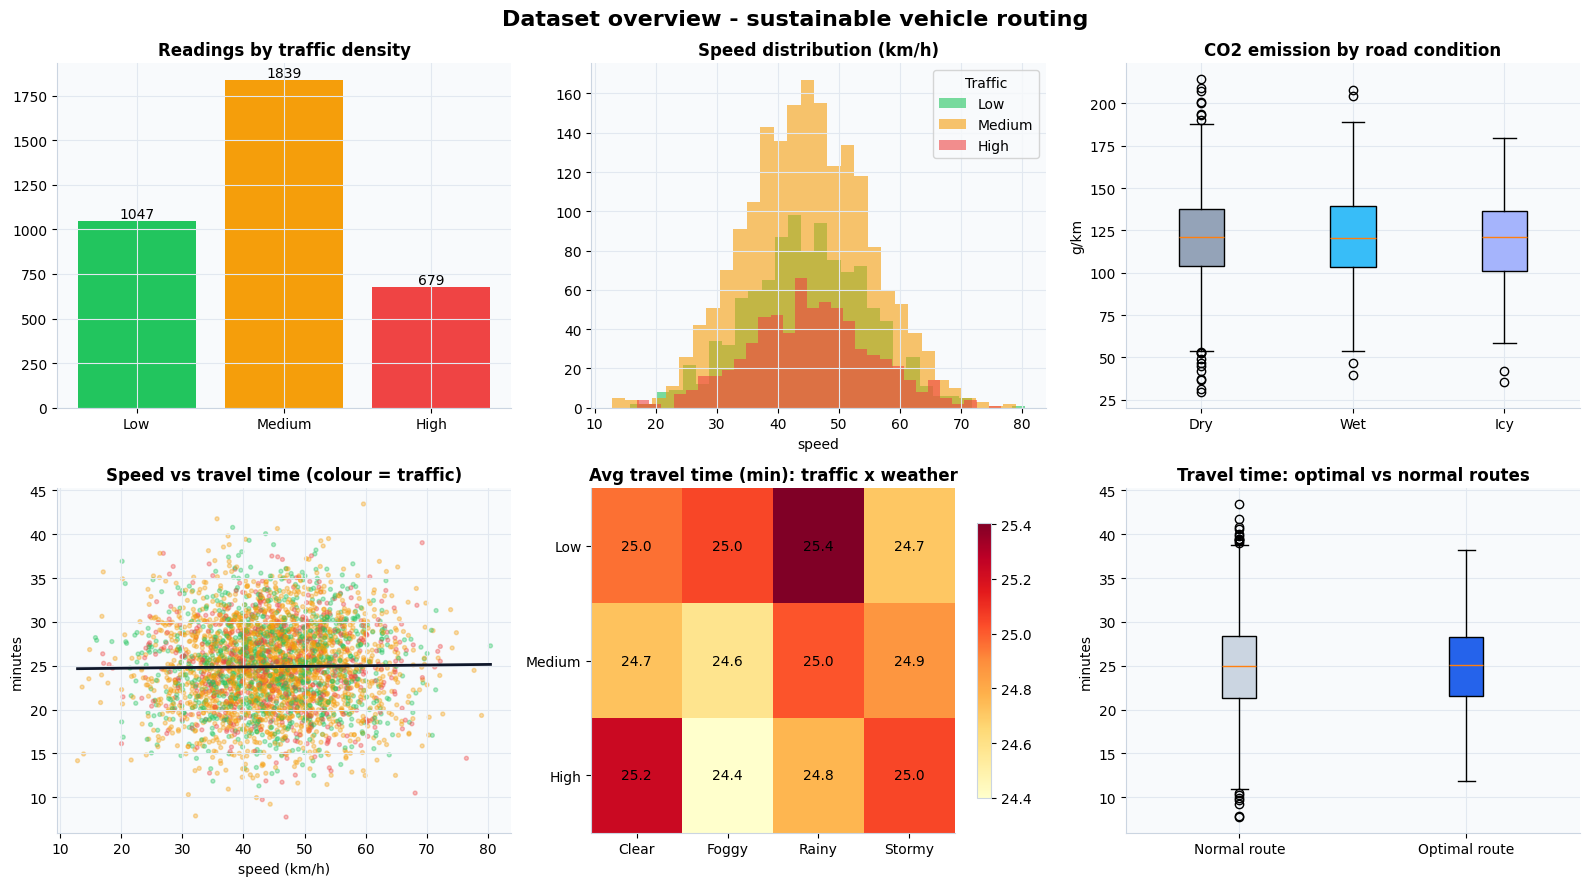

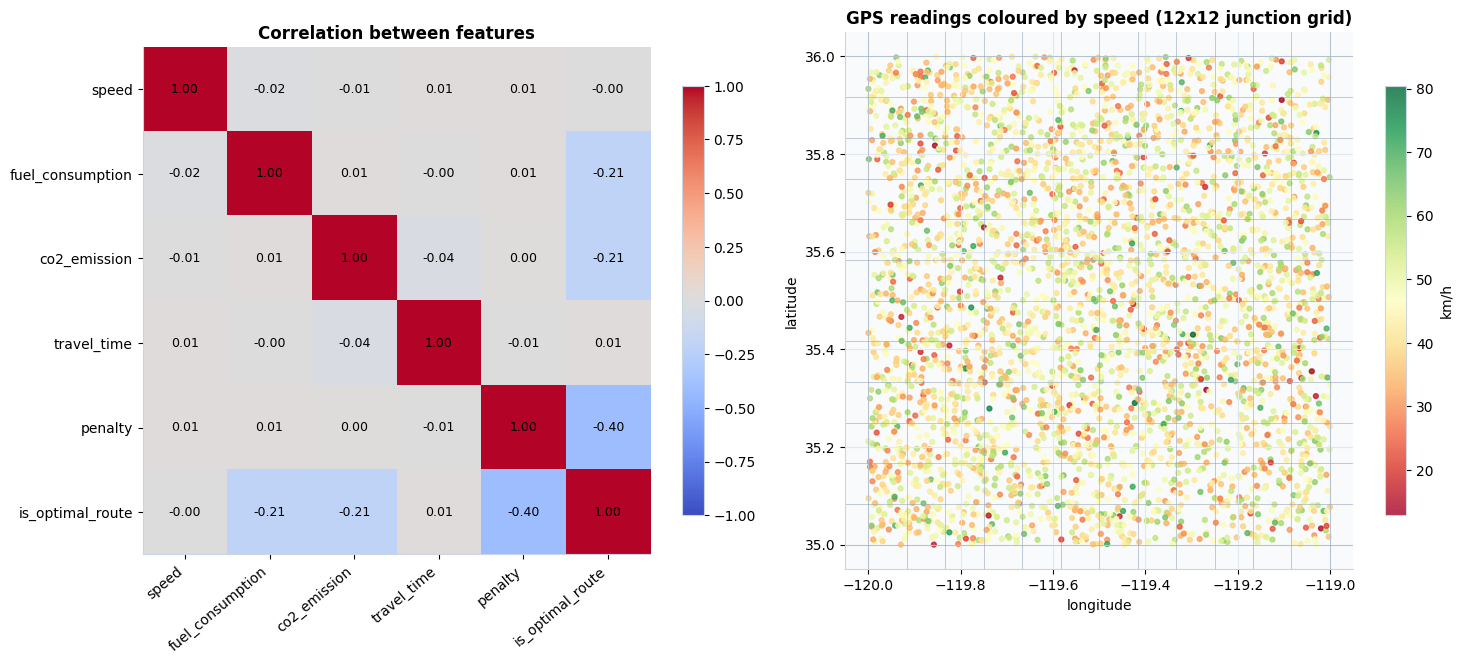

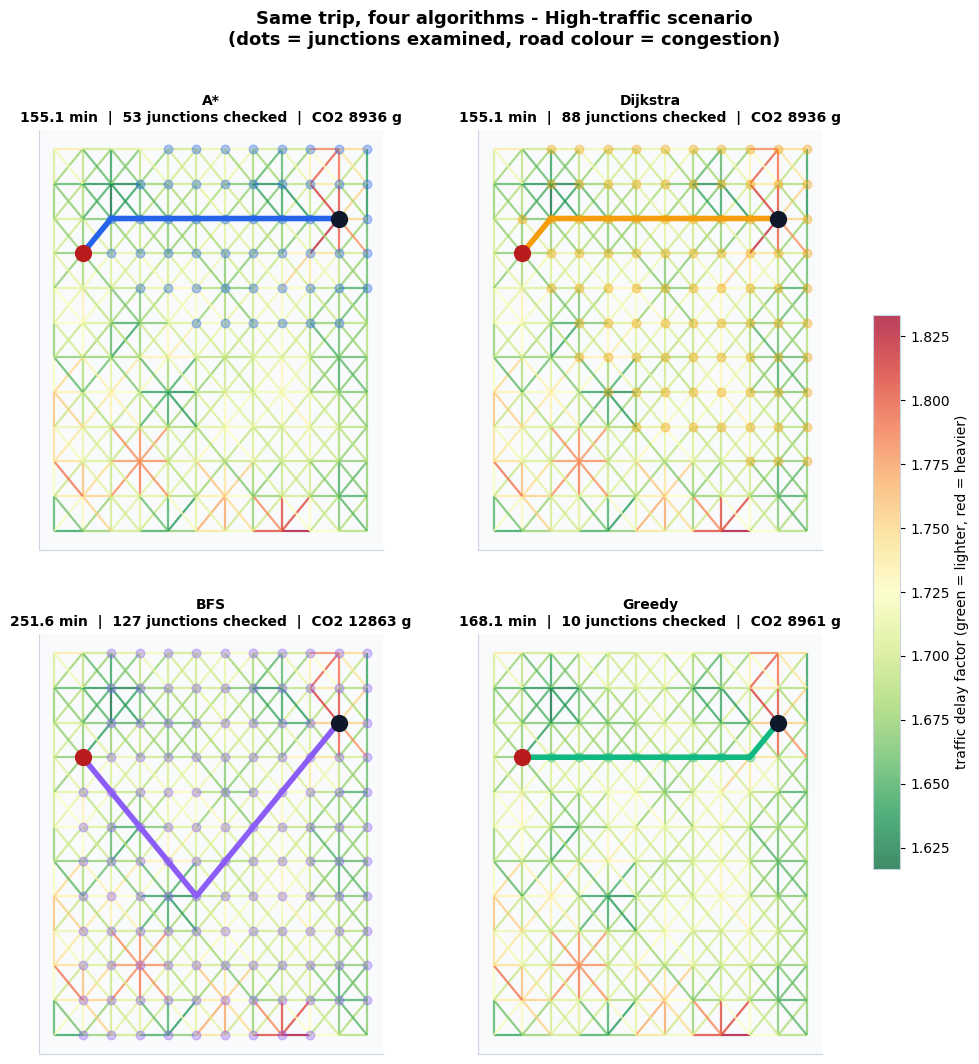

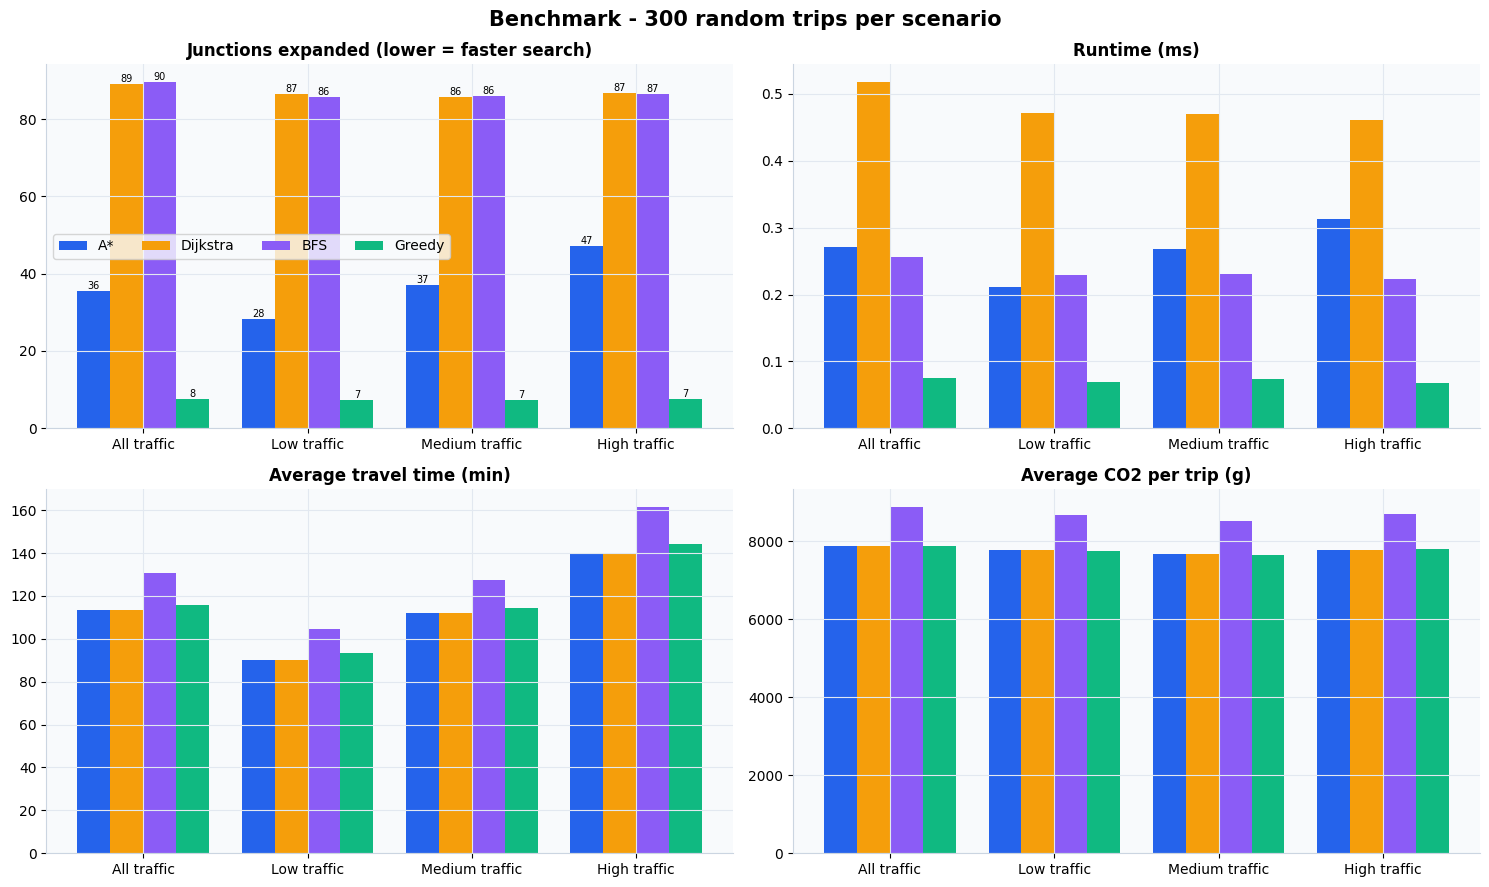

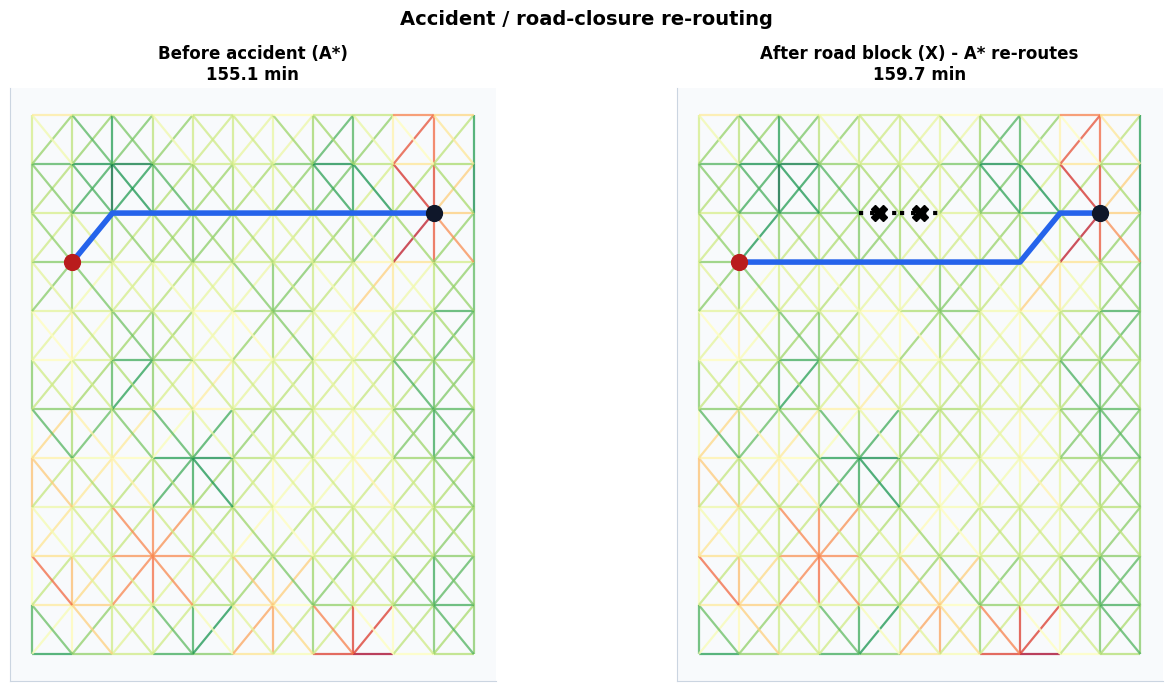

In [9]:
# --------------------------------------------------------------- main
def main():
    # Filter out Jupyter/Colab backend-specific arguments from sys.argv
    args = [a for a in sys.argv[1:] if not a.startswith("--") and a != "-f" and not a.endswith(".json")]
    path = Path(args[0]) if args else Path.cwd() / "sustainable_vehicle_routing.csv"
    if not path.exists():
        sys.exit(f"CSV not found: {path}\nPut the file next to this script or pass its path.")
    df = load_data(path)
    bounds = add_cells(df)
    print("\nBuilding road networks from the dataset ...")
    nets = {"All traffic": Network(df, bounds)}
    for lvl in ("Low", "Medium", "High"):
        nets[f"{lvl} traffic"] = Network(df[df.traffic_density == lvl], bounds)
    n = nets["All traffic"]
    print(f"  {len(n.pos)} junctions, {sum(len(v) for v in n.adj.values()) // 2} roads, "
          f"max speed used by heuristic = {n.vmax:.1f} km/h")

    print("\nCharts:")
    fig_overview(df); fig_corr_map(df)
    src, dst = pick_demo_pair(nets['High traffic'])
    res = fig_routes(nets["High traffic"], src, dst)
    bm = benchmark(nets); fig_benchmark(bm)
    after = fig_accident(nets["High traffic"], src, dst, res["A*"])

    OUT.mkdir(exist_ok=True)
    table = bm.groupby(["scenario", "algorithm"]).agg(
        avg_minutes=("minutes", "mean"), avg_km=("km", "mean"), avg_co2_g=("co2_g", "mean"),
        avg_fuel_l=("fuel_l", "mean"), avg_nodes_expanded=("nodes_expanded", "mean"),
        avg_runtime_ms=("runtime_ms", "mean"), optimal_pct=("optimal", lambda s: 100 * s.mean())).round(3)
    table = table.reindex(pd.MultiIndex.from_product([SCENARIOS, ALGOS]))
    table.to_csv(OUT / "benchmark_results.csv")
    pd.set_option("display.width", 200)
    print("\n================ BENCHMARK (averages over", TRIALS, "trips per scenario) ================")
    print(table.to_string())

    d = bm.groupby("algorithm")[["nodes_expanded", "minutes", "co2_g"]].mean()
    saving = 100 * (1 - d.loc["A*", "nodes_expanded"] / d.loc["Dijkstra", "nodes_expanded"])
    bfs_extra = 100 * (d.loc["BFS", "minutes"] / d.loc["A*", "minutes"] - 1)
    bfs_co2 = 100 * (d.loc["BFS", "co2_g"] / d.loc["A*", "co2_g"] - 1)
    opt = {a: 100 * bm[bm.algorithm == a].optimal.mean() for a in ALGOS}
    summary = (f"\n================ KEY FINDINGS ================\n"
               f"* A* is optimal in {opt['A*']:.0f}% of trips (same travel time as Dijkstra) but checks {saving:.0f}% fewer junctions.\n"
               f"* BFS ignores traffic: its trips take {bfs_extra:.1f}% longer and emit {bfs_co2:.1f}% more CO2 than A*.\n"
               f"* Greedy search is fast but optimal in only {opt['Greedy']:.0f}% of trips.\n"
               f"* Demo trip (High traffic): {res['A*']['min']:.1f} min; after a road block A* re-routes to {after['min']:.1f} min "
               f"(+{after['min'] - res['A*']['min']:.1f} min).\n")
    print(summary); (OUT / "summary.txt").write_text(summary, encoding="utf-8")
    print(f"All files are in: {OUT}")
    if "--no-show" not in sys.argv:
        plt.show()


if __name__ == "__main__":
    main()